# Mechanics and highly rated board games

Run `build_mechanics_dataset.ipynb` first. **Great = average rating of at least 8.** Use the same 2012–2021 sample with complete design metadata and known mechanic lists.

Four sections cover prevalence, a forest plot of all supported mechanics, co-occurrence and semantic groups, and a generative model. These are exploratory associations. The metadata and rating audiences can affect the results.

In [1]:
from pathlib import Path
import textwrap

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
import statsmodels.api as sm
from scipy.stats import false_discovery_control, hypergeom, binomtest

folder = Path("Boardgames") if Path("Boardgames").is_dir() else Path(".")
games = pd.read_csv(folder / "Data" / "boardgames_prepared.csv")
mechanic_columns = games.columns[games.columns.str.startswith("Mechanic: ")]
design_fields = [c for c in ["MinPlayers", "MaxPlayers", "MfgPlaytime", "MfgAgeRec",
                            "IsReimplementation", "Kickstarted"] if c in games]
required = ["AvgRating"] + design_fields + list(mechanic_columns)
sample = games.loc[games["YearPublished"].between(2012, 2021)].dropna(subset=required)
valid = sample["AvgRating"].between(1, 10)
if {"MinPlayers", "MaxPlayers"}.issubset(design_fields):
    valid &= sample["MinPlayers"].le(sample["MaxPlayers"])
sample = sample.loc[valid].reset_index(drop=True)
mechanics = sample[mechanic_columns].rename(columns=lambda s: s.removeprefix("Mechanic: ")).astype(int)
great = sample["AvgRating"].ge(8).astype(int)
print(f"{len(sample):,} games; {great.sum():,} rated 8+; {len(mechanics.columns)} mechanic indicators.")

9,439 games; 585 rated 8+; 195 mechanic indicators.


## 1. How common is each mechanic?

All mechanics are shown, sorted by the percentage of games containing them. The great-game rate is unadjusted.

In [2]:
prevalence = pd.DataFrame({
    "Games with": mechanics.sum(),
    "% with": 100 * mechanics.mean(),
    "Great games with": mechanics.loc[great.eq(1)].sum(),
    "% great when present": mechanics.apply(lambda s: 100 * great.loc[s.eq(1)].mean()),
}).sort_values("% with", ascending=False)
with pd.option_context("display.max_rows", None):
    display(prevalence.round(1))

,Games with,% with,Great games with,% great when present
Hand Management,2791,29.6,163,5.8
Dice Rolling,2639,28.0,329,12.5
Variable Player Powers,1832,19.4,210,11.5
Set Collection,1727,18.3,36,2.1
Open Drafting,1305,13.8,71,5.4
Cooperative Game,1274,13.5,122,9.6
Card Drafting,1130,12.0,62,5.5
Area Majority / Influence,1068,11.3,62,5.8
Modular Board,974,10.3,105,10.8
Tile Placement,957,10.1,40,4.2


## 2. All mechanics with enough data

Fit one logistic model containing all eligible mechanics together, publication-year controls and the log count of remaining mechanic tags. Require at least 100 games with and without a mechanic, and at least five great and five other games on both sides.

The forest plot includes every eligible mechanic. Diamonds show adjusted odds ratios and whiskers show pointwise 95% robust intervals. The red line is 1 (no modeled association). Closely linked labels such as `Card Drafting` and `Open Drafting` can reflect source coverage as well as design, making their separate estimates unstable. The table includes Benjamini–Yekutieli adjusted p-values for the many comparisons.

In [3]:
with_count = mechanics.sum()
great_with = mechanics.loc[great.eq(1)].sum()
other_with = with_count - great_with
eligible = ((with_count >= 100) & (len(sample) - with_count >= 100)
            & (great_with >= 5) & (great.sum() - great_with >= 5)
            & (other_with >= 5) & ((1 - great).sum() - other_with >= 5))
common = mechanics.loc[:, eligible]
year_controls = pd.get_dummies(sample["YearPublished"].astype(int).astype(str), drop_first=True, prefix="Year", dtype=float)
remaining_tags = np.log1p(mechanics.loc[:, ~eligible].sum(axis=1)).rename("Remaining tags")
design = sm.add_constant(pd.concat([common, year_controls, remaining_tags], axis=1).astype(float))
model = sm.GLM(great, design, family=sm.families.Binomial()).fit(cov_type="HC0", maxiter=200)
if not model.converged:
    raise RuntimeError("The joint mechanic model did not converge.")
intervals = model.conf_int().loc[common.columns]
effects = pd.DataFrame({
    "Odds ratio": np.exp(model.params.loc[common.columns]),
    "95% low": np.exp(intervals[0]), "95% high": np.exp(intervals[1]),
    "Games with": with_count.loc[common.columns],
    "Great games with": great_with.loc[common.columns],
    "Adjusted p": false_discovery_control(model.pvalues.loc[common.columns].to_numpy(), method="by"),
}).sort_values("Odds ratio")
print(f"Plotting all {len(effects)} eligible mechanics; {len(mechanics.columns) - len(effects)} have insufficient support.")

Plotting all 51 eligible mechanics; 144 have insufficient support.


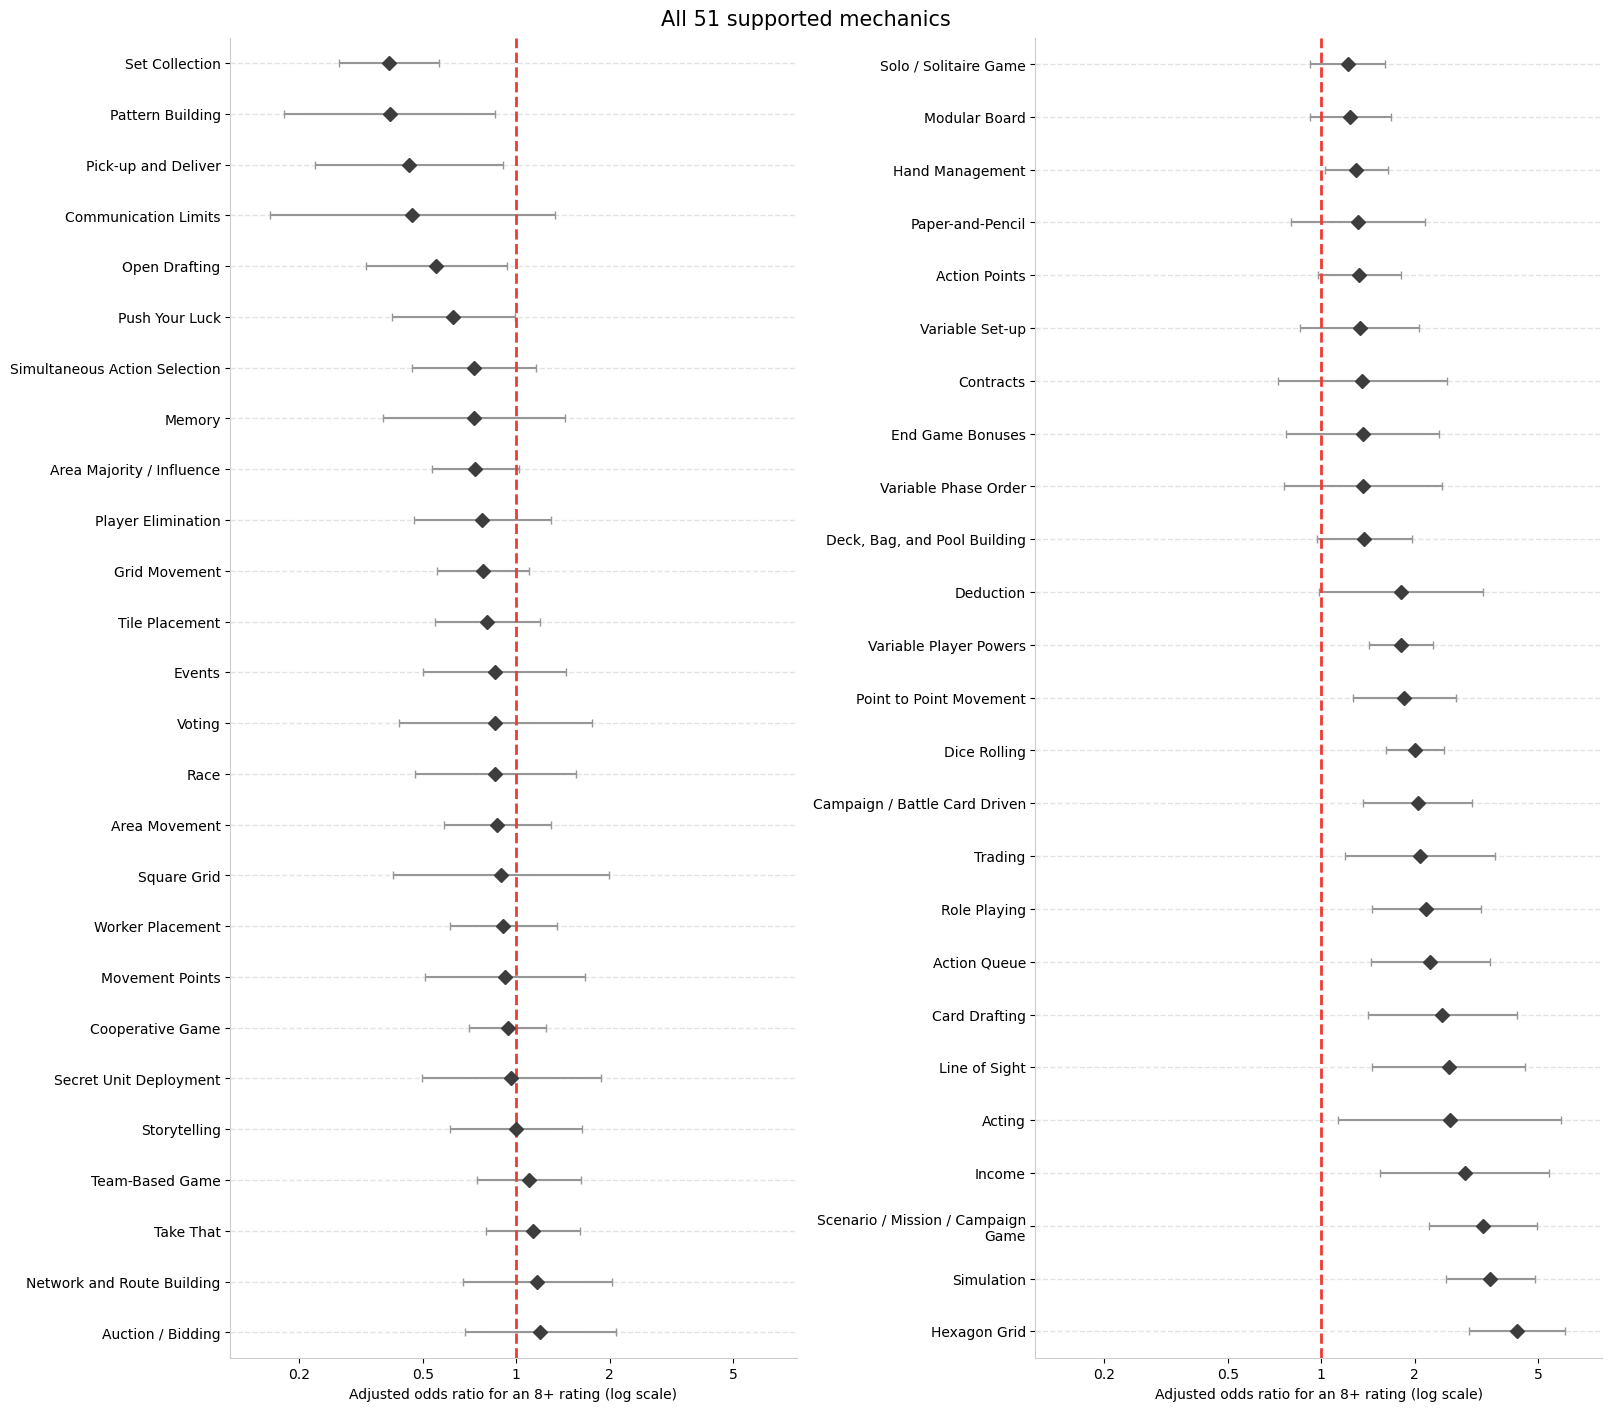

,Odds ratio,95% low,95% high,Games with,Great games with,Adjusted p
Set Collection,0.39,0.27,0.57,"1,727",36,3.5e-05
Pattern Building,0.39,0.18,0.85,500,7,0.28
Pick-up and Deliver,0.45,0.22,0.90,308,12,0.34
Communication Limits,0.46,0.16,1.33,116,5,1
Open Drafting,0.55,0.33,0.93,"1,305",71,0.34
Push Your Luck,0.63,0.40,0.99,736,26,0.53
Simultaneous Action Selection,0.73,0.46,1.16,645,29,1
Memory,0.73,0.37,1.44,477,10,1
Area Majority / Influence,0.74,0.54,1.02,"1,068",62,0.67
Player Elimination,0.78,0.47,1.29,422,21,1


In [4]:
def forest_panel(ax, table, reference=1, log_scale=False):
    positions = np.arange(len(table))
    ax.set_axisbelow(True)
    ax.grid(axis="y", color="#e3e3e3", linestyle="--", linewidth=1)
    ax.errorbar(table["Estimate"], positions, fmt="D", markersize=7,
                color="#3d3d3d", ecolor="#969696", elinewidth=1.5, capsize=3,
                xerr=[table["Estimate"] - table["Low"], table["High"] - table["Estimate"]])
    ax.axvline(reference, color="#ef3b36", linestyle="--", linewidth=2)
    ax.set_yticks(positions, [textwrap.fill(str(label), 32) for label in table.index], fontsize=10)
    ax.set_ylim(len(table) - 0.5, -0.5)
    ax.spines[["top", "right"]].set_visible(False)
    ax.spines[["left", "bottom"]].set_color("#cccccc")
    if log_scale:
        ax.set_xscale("log")
        ax.set_xlim(0.12, 8)
        ax.set_xticks([0.2, 0.5, 1, 2, 5], labels=["0.2", "0.5", "1", "2", "5"])
        ax.minorticks_off()


points = effects[["Odds ratio", "95% low", "95% high"]].set_axis(["Estimate", "Low", "High"], axis=1)
split = (len(points) + 1) // 2
fig, axes = plt.subplots(1, 2, figsize=(16, 0.50 * split + 1), layout="constrained")
for ax, panel in zip(axes, [points.iloc[:split], points.iloc[split:]]):
    forest_panel(ax, panel, log_scale=True)
    ax.set_xlabel("Adjusted odds ratio for an 8+ rating (log scale)")
fig.suptitle(f"All {len(effects)} supported mechanics", fontsize=15)
plt.show()
display(effects.style.format({
    "Odds ratio": "{:.2f}", "95% low": "{:.2f}", "95% high": "{:.2f}",
    "Games with": "{:,}", "Great games with": "{:,}", "Adjusted p": "{:.2g}",
}))

## 3. Mechanic grouping — both approaches

### A. Co-occurrence groups from shared games

Build links from the games in which mechanics occur together. Require at least five shared games and a Benjamini–Yekutieli adjusted p-value of at most 0.05 under a hypergeometric independence test. Weight links by phi correlation, then use the original Louvain grouping and overlap rule below.

Both approaches print their own core and additional memberships. Group numbers belong to each approach independently.

In [5]:
values = mechanics.to_numpy(dtype=np.int64)
support = values.sum(axis=0)
varying = (support > 0) & (support < len(values))
values = values[:, varying]
graph_names = mechanics.columns[varying]
left, right = np.triu_indices(len(graph_names), k=1)
together = (values.T @ values)[left, right]
a, b = support[varying][left], support[varying][right]
expected = a.astype(float) * b / len(values)
p = hypergeom.sf(together - 1, len(values), a, b)
q = false_discovery_control(p, method="by")
phi = (together - expected) / np.sqrt(expected * (len(values) - a) * (len(values) - b) / len(values))
links = np.flatnonzero((q <= 0.05) & (together >= 5) & (phi > 0))
graph = nx.Graph()
graph.add_weighted_edges_from((graph_names[left[i]], graph_names[right[i]], float(phi[i])) for i in links)

In [6]:
TARGET_GROUPS = 20
RESOLUTION = 2.5
OVERLAP_STRENGTH = 0.50

if graph.number_of_edges() == 0:
    raise ValueError("No mechanic pairs meet the co-occurrence criteria.")
partitions = [nx.community.louvain_communities(graph, resolution=RESOLUTION, seed=s)
              for s in [0, 17, 42]]
cores = min(partitions, key=lambda groups: (
    abs(len(groups) - TARGET_GROUPS),
    -nx.community.modularity(graph, groups, resolution=RESOLUTION),
))
cores = sorted(cores, key=lambda group: (-len(group), sorted(group)))
core_id = {name: i for i, core in enumerate(cores) for name in core}
groups = [set(core) for core in cores]
for name in sorted(graph):
    strength = np.zeros(len(cores))
    neighbors = np.zeros(len(cores), dtype=int)
    for neighbor, link in graph[name].items():
        group = core_id[neighbor]
        strength[group] += link["weight"]
        neighbors[group] += 1
    for group in np.flatnonzero((neighbors >= 2) & (strength >= OVERLAP_STRENGTH * strength.max())):
        groups[group].add(name)

cooccurrence_group_table = pd.DataFrame({
    "Core mechanics": [" · ".join(sorted(core)) for core in cores],
    "Additional mechanics": [" · ".join(sorted(group - core)) for core, group in zip(cores, groups)],
    "Size": [len(group) for group in groups],
}, index=pd.RangeIndex(1, len(groups) + 1, name="Group"))
display(cooccurrence_group_table.style.set_properties(**{"text-align": "left"}))
membership_count = pd.Series([sum(name in group for group in groups) for name in graph])
print(f"{len(groups)} co-occurrence groups; {int(membership_count.gt(1).sum())} mechanics appear in multiple groups.")
cooccurrence_cores = cores
cooccurrence_groups = groups

,Core mechanics,Additional mechanics,Size
Group,,,
1,Acting · Communication Limits · Deduction · Hidden Movement · Hidden Roles · Memory · Roles with Asymmetric Information · Secret Unit Deployment · Semi-Cooperative Game · Singing · Targeted Clues · Team-Based Game · Traitor Game · Voting,Player Elimination · Role Playing,16
2,"Auction: Dutch · Card Drafting · Deck Construction · Deck, Bag, and Pool Building · Delayed Purchase · Hand Management · I Cut, You Choose · Interrupts · Neighbor Scope · Open Drafting · Set Collection · Take That",Action Retrieval · Card Play Conflict Resolution · Player Elimination · Variable Player Powers,16
3,Chaining · Enclosure · Grid Coverage · Highest-Lowest Scoring · Layering · Map Addition · Melding and Splaying · Pattern Building · Pattern Movement · Slide / Push · Square Grid · Tile Placement,,12
4,Action / Event · Area Majority / Influence · Area Movement · Area-Impulse · Campaign / Battle Card Driven · Card Play Conflict Resolution · Events · Finale Ending · Force Commitment · Tug of War · Turn Order: Random,Point to Point Movement · Secret Unit Deployment,13
5,"Action Drafting · Action Retrieval · Automatic Resource Growth · Contracts · Follow · Increase Value of Unchosen Resources · Turn Order: Claim Action · Variable Phase Order · Worker Placement · Worker Placement with Dice Workers · Worker Placement, Different Worker Types",End Game Bonuses · Income · Race · Resource to Move · Rondel · Solo / Solitaire Game · Turn Order: Stat-Based,18
6,Action Points · Bias · Grid Movement · Mancala · Modular Board · Pick-up and Deliver · Point to Point Movement · Static Capture · Three Dimensional Movement · Variable Player Powers,Area Movement · Dice Rolling · Line of Sight · Map Addition · Race · Variable Phase Order,16
7,Action Queue · Critical Hits and Failures · Line of Sight · Measurement Movement · Movement Template · Player Judge · Prisoner's Dilemma · Programmed Movement · Rock-Paper-Scissors · Simultaneous Action Selection,,10
8,Auction / Bidding · Auction: Fixed Placement · Auction: Multiple Lot · Auction: Once Around · Auction: Sealed Bid · Auction: Turn Order Until Pass · Constrained Bidding · Multiple-Lot Auction · Selection Order Bid · Turn Order: Auction,,10
9,Closed Drafting · Drafting · End Game Bonuses · Hidden Victory Points · Income · Multi-Use Cards · Tags · Tech Trees / Tech Tracks · Turn Order: Pass Order · Turn Order: Progressive,Action Drafting · Contracts · Grid Coverage · Layering · Set Collection · Solo / Solitaire Game · Turn Order: Stat-Based · Variable Set-up · Victory Points as a Resource,19


19 co-occurrence groups; 37 mechanics appear in multiple groups.


### B. Semantic groups from name embeddings

Embed each mechanic's name using local All-MiniLM, then cluster the normalized vectors into 20 core groups with K-means. Grouping uses the wording of the labels. Short or ambiguous names can mix concepts, so the table includes mean core similarity for review.

A mechanic also joins another group when its cosine similarity to that group's centroid is at least 0.45 and at least 80% of its closest-centroid similarity. Each mechanic keeps its core group. This provides overlapping semantic memberships.

In [7]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import normalize

with np.load(folder / "Data" / "mechanic_embeddings.npz", allow_pickle=False) as saved:
    names = saved["names"].astype(str)
    embeddings = saved["vectors"].copy()
    embedding_model = saved["model"].item()
if not np.array_equal(names, mechanics.columns.to_numpy()):
    raise ValueError("Mechanic names changed. Rerun build_mechanics_dataset.ipynb.")
embeddings = normalize(embeddings)
print(f"Semantic grouping uses {embedding_model}: {embeddings.shape}.")

Semantic grouping uses all-minilm:latest: (195, 384).


In [8]:
TARGET_GROUPS = 20
OVERLAP_STRENGTH = 0.80
MIN_SIMILARITY = 0.45

labels = KMeans(n_clusters=TARGET_GROUPS, n_init=30, random_state=17).fit_predict(embeddings)
cores = [np.flatnonzero(labels == group) for group in range(TARGET_GROUPS)]
centers = normalize(np.array([embeddings[core].mean(axis=0) for core in cores]))
similarity = embeddings @ centers.T
membership = ((similarity >= MIN_SIMILARITY)
              & (similarity >= OVERLAP_STRENGTH * similarity.max(axis=1, keepdims=True)))
membership[np.arange(len(names)), labels] = True

rows = []
for group, core in enumerate(cores):
    ordered_core = sorted(core, key=lambda i: -similarity[i, group])
    extra = np.flatnonzero(membership[:, group] & (labels != group))
    ordered_extra = sorted(extra, key=lambda i: -similarity[i, group])
    rows.append({"Core mechanics": " · ".join(names[ordered_core]),
                 "Additional mechanics": " · ".join(names[ordered_extra]),
                 "Size": int(membership[:, group].sum()),
                 "Mean core cosine": float(similarity[core, group].mean())})
semantic_group_table = pd.DataFrame(rows, index=pd.RangeIndex(1, TARGET_GROUPS + 1, name="Group"))
display(semantic_group_table.style.format({"Mean core cosine": "{:.2f}"}).set_properties(**{"text-align": "left"}))
overlapping = pd.DataFrame({
    "Mechanic": names,
    "Groups": [", ".join(str(g + 1) for g in np.flatnonzero(row)) for row in membership],
    "Group count": membership.sum(axis=1),
}).set_index("Mechanic")
display(overlapping.loc[overlapping["Group count"] > 1])
print(f"{TARGET_GROUPS} groups cover all {len(names)} mechanics; "
      f"{int((membership.sum(axis=1) > 1).sum())} mechanics appear in multiple groups.")
semantic_cores = [set(names[core]) for core in cores]
semantic_groups = [set(names[membership[:, group]]) for group in range(TARGET_GROUPS)]

,Core mechanics,Additional mechanics,Size,Mean core cosine
Group,,,,
1,Lose a Turn · Trick-taking · Roll / Spin and Move · Kill Steal · Catch the Leader · Push Your Luck · Flicking · Re-rolling and Locking · Take That · Critical Hits and Failures,Dice Rolling · Rock-Paper-Scissors,12,0.57
2,Turn Order: Pass Order · Turn Order: Stat-Based · Auction: Turn Order Until Pass · Turn Order: Random · Ordering · Turn Order: Progressive · Turn Order: Time Track · Turn Order: Claim Action · Turn Order: Role Order · Selection Order Bid · Order Counters · Variable Phase Order · Delayed Purchase,Turn Order: Auction,14,0.69
3,Auction / Bidding · Auction: Once Around · Auction: Multiple Lot · Auction: Fixed Placement · Auction: Sealed Bid · Auction: Dexterity · Auction: English · Auction Compensation · Multiple-Lot Auction · Auction: Dutch · Turn Order: Auction · Auction: Dutch Priority · Closed Economy Auction · Constrained Bidding · Bids As Wagers · Predictive Bid,Auction: Turn Order Until Pass · Selection Order Bid,18,0.81
4,Action Points · Action / Event · Action Retrieval · Action Queue · Simultaneous Action Selection · Role Playing · Acting · Action Timer · Targeted Clues · Hidden Victory Points · Hidden Roles · Passed Action Token · Victory Points as a Resource · Questions and Answers · Line of Sight · Physical Removal,Action Drafting · Events,18,0.58
5,Multi-Use Cards · Campaign / Battle Card Driven · Command Cards · Card Play Conflict Resolution · Once-Per-Game Abilities,Solo / Solitaire Game,6,0.72
6,Resource Queue · Automatic Resource Growth · Resource to Move · Increase Value of Unchosen Resources · Memory · Random Production · Communication Limits,,7,0.62
7,Movement Points · Relative Movement · Area Movement · Three Dimensional Movement · Track Movement · Hidden Movement · Point to Point Movement · Programmed Movement · Impulse Movement · Measurement Movement · Movement Template · Slide / Push · Moving Multiple Units · Area-Impulse · Chit-Pull System,Pattern Movement · Grid Movement · Roll / Spin and Move,18,0.69
8,Multiple Maps · Pieces as Map · Layering · Map Addition · Map Reduction · Map Deformation · Chaining · Melding and Splaying · Paper-and-Pencil · Crayon Rail System · Stacking and Balancing · Tags · Enclosure,,13,0.59
9,"Worker Placement with Dice Workers · Worker Placement · Worker Placement, Different Worker Types · Different Dice Movement · Dice Rolling",,5,0.74


,Groups,Group count
Mechanic,,
Acting,"4, 18",2
Action Drafting,"4, 12",2
Auction: Turn Order Until Pass,"2, 3",2
Dice Rolling,"1, 9",2
Events,"4, 18",2
Grid Movement,"7, 11",2
Hidden Victory Points,"4, 10",2
Paper-and-Pencil,"8, 12",2
Pattern Movement,"7, 19",2


20 groups cover all 195 mechanics; 16 mechanics appear in multiple groups.


## 4. Generative model and evaluation

A mixture of Bernoulli distributions learns mechanic styles separately for 8+ and other games. Fit on 2012–2016, select model size and smoothing on 2017–2018, then refit through 2018 and evaluate on 2019–2021. Scores compare how likely a mechanic set is under the two classes.

The later games have been explored before, so this temporal evaluation remains exploratory. Compare with mechanic count and logistic regression before drawing design conclusions.

In [9]:
from scipy.special import logsumexp, expit
from scipy.optimize import brentq
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.metrics import average_precision_score, roc_auc_score, mean_absolute_error, r2_score, brier_score_loss
from threadpoolctl import threadpool_limits

mx = mechanics.to_numpy(dtype=float)
my = great.to_numpy(dtype=int)
years = sample["YearPublished"].to_numpy()
development = years <= 2016
validation = (years >= 2017) & (years <= 2018)
evaluation = years >= 2019


def component_scores(values, model):
    weights, probabilities, objective = model
    return (values @ np.log(probabilities).T
            + (1 - values) @ np.log1p(-probabilities).T + np.log(weights))


def fit_mixture(values, n_styles, smoothing, seed):
    # Shrink component probabilities toward the class-wide mechanic frequencies.
    base = (values.sum(axis=0) + 1) / (len(values) + 2)
    labels = KMeans(n_clusters=n_styles, n_init=1, random_state=seed).fit_predict(values)
    responsibility = np.eye(n_styles)[labels]
    previous = None
    for step in range(300):
        size = responsibility.sum(axis=0)
        weights = (size + 1) / (len(values) + n_styles)
        probabilities = (responsibility.T @ values + smoothing * base) / (size[:, None] + smoothing)
        joint = component_scores(values, (weights, probabilities, None))
        likelihood = logsumexp(joint, axis=1)
        objective = (likelihood.sum() + np.log(weights).sum()
                     + smoothing * (base * np.log(probabilities)
                                    + (1 - base) * np.log1p(-probabilities)).sum())
        responsibility = np.exp(joint - likelihood[:, None])
        if previous is not None and abs(objective - previous) < 1e-5 * (1 + abs(previous)):
            break
        previous = objective
    return weights, probabilities, objective


def fit_generative(mask, n_styles, smoothing):
    models = []
    for label in [0, 1]:
        starts = [fit_mixture(mx[mask & (my == label)], n_styles, smoothing, seed)
                  for seed in [17, 42, 123]]
        models.append(max(starts, key=lambda model: model[2]))
    return models


def generative_score(values, models):
    return (logsumexp(component_scores(values, models[1]), axis=1)
            - logsumexp(component_scores(values, models[0]), axis=1))

In [10]:
search_rows = []
with threadpool_limits(limits=1):
    for smoothing in [2, 10, 50]:
        for n_styles in [1, 2, 4, 6, 8, 12]:
            models = fit_generative(development, n_styles, smoothing)
            scores = generative_score(mx[validation], models)
            search_rows.append({"Styles per class": n_styles, "Smoothing": smoothing,
                                "Validation AP": average_precision_score(my[validation], scores)})
    model_search = pd.DataFrame(search_rows).sort_values("Validation AP", ascending=False)
    best = model_search.iloc[0]
    models = fit_generative(~evaluation, int(best["Styles per class"]), best["Smoothing"])
    generative_scores = generative_score(mx[evaluation], models)

print(f"Validation selected {int(best['Styles per class'])} styles per class.")

Validation selected 6 styles per class.


,AUC,AP,Selected games,Great games,% great,95% low,95% high
Model,,,,,,,
Mechanic count,0.705,0.256,257,87,33.852,28.342,39.838
Generative mixture,0.755,0.335,257,103,40.078,34.275,46.173
Logistic regression,0.780,0.408,257,122,47.471,41.448,53.568
Average-rating regression,0.761,0.351,257,111,43.191,37.279,49.303


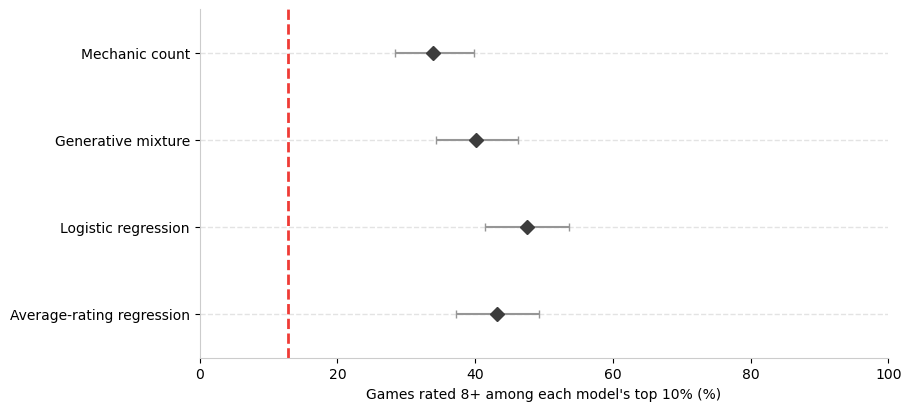

In [11]:
with threadpool_limits(limits=1):
    options = []
    for c in [0.01, 0.1, 1, 10]:
        candidate = LogisticRegression(C=c, max_iter=2000).fit(mx[development], my[development])
        options.append((average_precision_score(my[validation], candidate.decision_function(mx[validation])), c))
    logistic = LogisticRegression(C=max(options)[1], max_iter=2000).fit(mx[~evaluation], my[~evaluation])
    # A second objective predicts average rating rather than the 8+ label.
    ratings = sample["AvgRating"].to_numpy()
    rating_options = []
    for alpha in [0.1, 1, 10, 100, 1000]:
        candidate = Ridge(alpha=alpha).fit(mx[development], ratings[development])
        error = mean_absolute_error(ratings[validation], candidate.predict(mx[validation]))
        rating_options.append((error, alpha))
    rating_regression = Ridge(alpha=min(rating_options)[1]).fit(mx[~evaluation], ratings[~evaluation])
    rating_predictions = rating_regression.predict(mx[evaluation])
    validation_rating = Ridge(alpha=min(rating_options)[1]).fit(mx[development], ratings[development])
    rating_offset = np.mean(ratings[validation] - validation_rating.predict(mx[validation]))
    validation_classifier = LogisticRegression(C=max(options)[1], max_iter=2000).fit(mx[development], my[development])
    validation_score = validation_classifier.decision_function(mx[validation])
    probability_offset = brentq(lambda offset: expit(validation_score + offset).mean() - my[validation].mean(), -10, 10)
scores = {"Mechanic count": mx[evaluation].sum(axis=1), "Generative mixture": generative_scores,
          "Logistic regression": logistic.decision_function(mx[evaluation]),
          "Average-rating regression": rating_predictions}
rows = []
top_n = int(np.ceil(0.10 * evaluation.sum()))
for name, score in scores.items():
    tie_break = np.random.default_rng(17).random(len(score))
    top = np.lexsort((tie_break, -score))[:top_n]
    hits = int(my[evaluation][top].sum())
    interval = binomtest(hits, top_n).proportion_ci(method="wilson")
    rows.append({"Model": name, "AUC": roc_auc_score(my[evaluation], score),
                 "AP": average_precision_score(my[evaluation], score), "Selected games": top_n,
                 "Great games": hits, "Estimate": 100 * hits / top_n,
                 "Low": 100 * interval.low, "High": 100 * interval.high})
benchmarks = pd.DataFrame(rows).set_index("Model")
display(benchmarks.rename(columns={"Estimate": "% great", "Low": "95% low", "High": "95% high"}).round(3))
fig, ax = plt.subplots(figsize=(9, 4), layout="constrained")
forest_panel(ax, benchmarks, reference=100 * my[evaluation].mean())
ax.set(xlim=(0, 100), xlabel="Games rated 8+ among each model's top 10% (%)")
plt.show()

### Does the ranking work within individual release years?

Rank games separately within each later year and take the top 10%. This checks whether the pooled result depends mainly on selecting games from the most recent, higher-rated cohort. The models remain fitted on games through 2018.

In [12]:
year_rows = []
classifier_scores = scores["Logistic regression"]
for year in [2019, 2020, 2021]:
    in_year = years[evaluation] == year
    values = classifier_scores[in_year]
    tie_break = np.random.default_rng(17).random(len(values))
    top = np.lexsort((tie_break, -values))[:int(np.ceil(0.10 * len(values)))]
    labels = my[evaluation][in_year]
    year_rows.append({"Year": year, "All games": len(labels),
                      "Overall % great": 100 * labels.mean(), "Selected games": len(top),
                      "Great games selected": int(labels[top].sum()),
                      "Selected % great": 100 * labels[top].mean()})
display(pd.DataFrame(year_rows).set_index("Year").round(1))

,All games,Overall % great,Selected games,Great games selected,Selected % great
Year,,,,,
2019,1149,8.4,115,52,45.2
2020,820,13.9,82,37,45.1
2021,598,19.6,60,36,60.0


### Ranking versus predicting an exact score

The extra benchmark predicts average rating using ridge regression, with its penalty chosen by validation absolute error. Its ranking is evaluated using the same 8+ criterion. Negative R² means worse squared error than a constant at the actual later-period mean, which is unknown in advance.

To check temporal drift, learn a rating offset and a classifier log-odds offset from 2017–2018 predictions made by models fitted through 2016. Apply these earlier-period corrections to the models refitted through 2018. The corrections change absolute estimates while preserving the rankings.

In [13]:
rating_checks = []
for name, prediction in {
    "Earlier mean": np.full(evaluation.sum(), ratings[~evaluation].mean()),
    "Rating regression": rating_predictions,
    "Rating regression + earlier offset": rating_predictions + rating_offset,
}.items():
    rating_checks.append({"Model": name,
                          "Mean absolute error": mean_absolute_error(ratings[evaluation], prediction),
                          "Mean prediction error": np.mean(prediction - ratings[evaluation]),
                          "R²": r2_score(ratings[evaluation], prediction)})
display(pd.DataFrame(rating_checks).set_index("Model").round(3))
probability_checks = []
for name, offset in {"Classifier": 0, "Classifier + earlier offset": probability_offset}.items():
    probability = expit(scores["Logistic regression"] + offset)
    probability_checks.append({"Model": name, "Average predicted % great": 100 * probability.mean(),
                               "Actual % great": 100 * my[evaluation].mean(),
                               "Brier score": brier_score_loss(my[evaluation], probability)})
display(pd.DataFrame(probability_checks).set_index("Model").round(3))
print(f"Average observed rating: {ratings[~evaluation].mean():.2f} in earlier games, {ratings[evaluation].mean():.2f} in later games.")

,Mean absolute error,Mean prediction error,R²
Model,,,
Earlier mean,0.753,-0.574,-0.612
Rating regression,0.613,-0.409,-0.112
Rating regression + earlier offset,0.514,-0.152,0.155


,Average predicted % great,Actual % great,Brier score
Model,,,
Classifier,5.493,12.778,0.101
Classifier + earlier offset,10.127,12.778,0.095


Average observed rating: 6.61 in earlier games, 7.18 in later games.


In [14]:
great_weights, great_probabilities, objective = models[1]
profile = component_scores(mx[evaluation], models[1]).argmax(axis=1)
style_rows = []
for i, probabilities in enumerate(great_probabilities):
    strongest = np.argsort(-probabilities)[:6]
    members = profile == i
    style_rows.append({
        "Profile": i + 1,
        "Strongest mechanics (model probability)": " · ".join(
            f"{mechanics.columns[j]} ({100 * probabilities[j]:.0f}%)" for j in strongest),
        "Earlier great-game mixture share %": 100 * great_weights[i],
        "Later games": int(members.sum()),
        "Later great games": int(my[evaluation][members].sum()),
        "Later % great": 100 * my[evaluation][members].mean() if members.any() else np.nan,
    })
style_table = pd.DataFrame(style_rows).set_index("Profile")
display(style_table.round(1).style.format({
    "Earlier great-game mixture share %": "{:.1f}", "Later % great": "{:.1f}",
}, na_rep="—").set_properties(**{"text-align": "left"}))

,Strongest mechanics (model probability),Earlier great-game mixture share %,Later games,Later great games,Later % great
Profile,,,,,
1,"Hand Management (48%) · Variable Player Powers (44%) · Dice Rolling (38%) · Card Drafting (27%) · Open Drafting (27%) · Deck, Bag, and Pool Building (18%)",25.9,953,80,8.4
2,Dice Rolling (78%) · Area Majority / Influence (78%) · Variable Set-up (77%) · Variable Player Powers (58%) · Movement Points (52%) · Card Play Conflict Resolution (51%),2.7,30,12,40.0
3,Solo / Solitaire Game (41%) · Hand Management (39%) · Network and Route Building (35%) · Card Drafting (32%) · Variable Set-up (32%) · Worker Placement (32%),13.0,585,41,7.0
4,Cooperative Game (87%) · Variable Player Powers (73%) · Dice Rolling (67%) · Solo / Solitaire Game (59%) · Hand Management (52%) · Scenario / Mission / Campaign Game (48%),10.7,269,65,24.2
5,Dice Rolling (91%) · Movement Points (87%) · Hexagon Grid (72%) · Simulation (72%) · Grid Movement (53%) · Scenario / Mission / Campaign Game (52%),7.1,60,30,50.0
6,Dice Rolling (83%) · Simulation (47%) · Hexagon Grid (44%) · Action Points (18%) · Variable Player Powers (16%) · Line of Sight (15%),40.6,670,100,14.9


### Sample candidate combinations

The next cell draws three sets of 4–8 mechanic tags from the cooperative profile. These are illustrative generated sets for design and playtesting.

In [15]:
coop_profile = great_probabilities[:, list(mechanics.columns).index("Cooperative Game")].argmax()
rng = np.random.default_rng(17)
generated = []
for draw in rng.binomial(1, great_probabilities[coop_profile], size=(100, mx.shape[1])):
    if 4 <= draw.sum() <= 8:
        generated.append(" · ".join(mechanics.columns[draw == 1]))
    if len(generated) == 3:
        break
generated_table = pd.DataFrame(
    {"Generated mechanics": generated},
    index=pd.RangeIndex(1, len(generated) + 1, name="Draw"),
)
display(generated_table.style.set_properties(**{"text-align": "left"}))

,Generated mechanics
Draw,
1,Area Movement · Cooperative Game · Hand Management · Point to Point Movement · Role Playing · Solo / Solitaire Game · Turn Order: Role Order · Variable Player Powers
2,Action Points · Chit-Pull System · Cooperative Game · Dice Rolling · Interrupts · Role Playing · Solo / Solitaire Game · Take That
3,Cooperative Game · Dice Rolling · Grid Movement · Hand Management · Ratio / Combat Results Table · Role Playing · Scenario / Mission / Campaign Game · Variable Player Powers


The joint-model intervals describe conditional associations among these recorded features. Their ordering depends on the controls and correlations between mechanics. The generative styles provide ideas, while logistic regression gives the stronger 8+ ranking in this temporal evaluation. Its ranking works within each later year as well. Simple corrections learned from earlier years improve exact-score and probability estimates, although some underprediction remains in the later cohort. These exploratory results do not establish which mechanic will make a new game successful.